# Примеры рекомендаций: DreamRecText, SASRec и kNN по тексту

Что именно выдают модели на тесте toys (leave-one-out, последний товар пользователя):

* **DreamRecText** — DreamRec на замороженных текстовых эмбеддингах Qwen (PCA + whitening);
* **SASRec** — базовая модель на обучаемых ID-эмбеддингах;
* **kNN (текст)** — бейзлайн без обучения: ближайшие по косинусу соседи последнего товара истории
  в сырых текстовых эмбеддингах Qwen.

Для каждого тестового пользователя считается полный top-K по всему каталогу и ранг таргета.
Дальше — распределение рангов, примеры выдачи: хорошие (таргет в top-10) и плохие (таргет далеко)
для каждой модели, а также случаи, где модели расходятся.

Модели собираются **по конфигу, сохранённому в самом прогоне** (первая строка `log_val.csv`),
а не по текущему yaml: yaml после обучения могли поменять.

In [1]:
import json, os, sys, tempfile
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)                          # пути в конфигах относительны корня проекта
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from IPython.display import Markdown, display

from builders import load_model_config
from data import build_dataloaders
from train import seeded

pd.set_option('display.max_colwidth', 90)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Корень проекта: {ROOT} | device: {device}')

Корень проекта: d:\Skoltech\Thesis\DiffText4Rec | device: cuda


## Параметры

In [2]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
RUNS = {                                  # имя модели → папка прогона с best.pt и log_val.csv
    'DreamRecText': 'checkpoints/toys/dreamrec_text',
    'SASRec':       'checkpoints/toys/sasrec_d256',
}
RETRIEVAL = {'DreamRecText': 'cosine'}    # переопределить ретривал (dot / cosine / l2); нет ключа — из конфига прогона

# Бейзлайн без обучения: ближайшие соседи последнего товара истории по сырым текстовым
# эмбеддингам (те же, что у DreamRecText до PCA/whitening), косинус
KNN              = 'kNN (текст)'
KNN_EXCLUDE_LAST = False                   # не рекомендовать сам последний товар
PAIRS = [('DreamRecText', 'SASRec'), ('DreamRecText', KNN)]   # пары для парных сравнений

SPLIT         = 'test'
SAMPLING_SEED = 1       # сид сэмплинга DreamRec: при другом сиде выдача немного другая
METRIC_K      = 20      # K для метрик HR@K / NDCG@K
TOP_K         = 10      # примеры: «хорошо» — таргет в top-TOP_K, в таблицах показывается top-TOP_K
BAD_RANK      = 1000    # «плохо» — ранг таргета ≥ BAD_RANK (из 20 259)
N_STORE       = 20      # сколько позиций выдачи хранить (≥ TOP_K)
N_EXAMPLES    = 3       # примеров на категорию
EXAMPLE_SEED  = 0       # какие пользователи попадут в примеры
HISTORY_SHOWN = 8       # последних товаров истории в примере

## Модели

In [3]:
def run_config(run_dir: Path) -> dict:
    # Весь конфиг прогона — JSON в первой строке log_val.csv после '# '
    with open(run_dir / 'log_val.csv', encoding='utf-8') as f:
        return json.loads(f.readline()[2:])['config']


def load_run(run_dir: str):
    run_dir = Path(run_dir)
    raw = run_config(run_dir)
    # load_model_config читает yaml — пишем конфиг прогона во временный файл
    with tempfile.NamedTemporaryFile('w', suffix='.yaml', delete=False, encoding='utf-8') as f:
        yaml.safe_dump(raw, f, allow_unicode=True)
    spec, cfg = load_model_config(f.name)
    os.unlink(f.name)

    model = spec.build(cfg).to(device).eval()
    ckpt = torch.load(run_dir / 'best.pt', map_location='cpu', weights_only=False)
    model.load_state_dict(ckpt['model_state'])
    return model, cfg, ckpt


models = {}
for name, run_dir in RUNS.items():
    model, cfg, ckpt = load_run(run_dir)
    generative = cfg.model_type != 'sasrec'
    metric = RETRIEVAL.get(name, model.retrieval_metric)
    models[name] = dict(model=model, cfg=cfg, generative=generative, metric=metric,
                        num_steps=cfg.eval.num_sample_steps, w_cfg=getattr(cfg.model, 'w_cfg', 0.0))
    print(f'{name:13s} {type(model).__name__:13s} эпоха {ckpt["epoch"]:3d} | ретривал {metric} | '
          f'val {{{", ".join(f"{k} {v:.4f}" for k, v in ckpt["metrics"].items())}}}')

# kNN: сырые текстовые эмбеддинги из того же файла, что у DreamRecText
from data import load_item_embeddings

text_cfg = models['DreamRecText']['cfg']
knn_table = F.normalize(torch.from_numpy(load_item_embeddings(text_cfg.data.emb_path)).to(device), dim=-1)
models[KNN] = dict(knn=True, generative=False, cfg=text_cfg, table=knn_table, metric='cosine')
print(f'{KNN:13s} соседи последнего товара по {text_cfg.data.emb_path}, {tuple(knn_table.shape)}')

Item embeddings: (20259, 1024)
Loading whitening from cache: data\processed\toys\whitening_cache_k1024_pc.npz
DreamRecText  DreamRecText  эпоха  20 | ретривал cosine | val {HR@10 0.0522, NDCG@10 0.0289, HR@20 0.0728, NDCG@20 0.0341}
SASRec        SASRec        эпоха  45 | ретривал dot | val {HR@10 0.0569, NDCG@10 0.0320, HR@20 0.0822, NDCG@20 0.0384}
kNN (текст)   соседи последнего товара по ./data/processed/toys/qwen3-embedding-0.6b_text.pickle, (20259, 1024)


## Данные: тексты товаров, популярность, тестовые пользователи

Название товара — строка `title:` из `items.parquet`, магазин — `store_title:`.
Популярность — число появлений товара в train (в историях и таргетах).

In [4]:
cfg0 = next(iter(models.values()))['cfg']
DATA = Path(cfg0.data.data_dir)
N_ITEMS = cfg0.data.n_items

items = pd.read_parquet(DATA / 'items.parquet')


def field(text: str, key: str) -> str:
    for line in text.split('\n'):
        if line.startswith(key + ':'):
            return line[len(key) + 1:].strip()
    return ''


TITLE = items['text'].map(lambda t: field(t, 'title')).to_numpy()
STORE = items['text'].map(lambda t: field(t, 'store_title')).to_numpy()

train = pd.read_pickle(DATA / 'train_data.df')
POP = np.bincount(np.concatenate([np.concatenate(train['seq'].to_numpy()), train['next'].to_numpy()]),
                  minlength=N_ITEMS)[:N_ITEMS]

split_df = pd.read_pickle(DATA / f'{SPLIT}_data.df')
TARGET = split_df['next'].to_numpy()
print(f'{SPLIT}: {len(split_df):,} пользователей | товаров {N_ITEMS:,} | '
      f'таргет не встречается в train у {(POP[TARGET] == 0).mean():.1%}')


def name_of(i: int, width: int = 70) -> str:
    title = TITLE[i] if len(TITLE[i]) <= width else TITLE[i][:width - 1] + '…'
    return f'{title}  [{STORE[i]}]' if STORE[i] else title

test: 23,845 пользователей | товаров 20,259 | таргет не встречается в train у 0.0%


## Выдача и ранг таргета

Для каждого пользователя — top-`N_STORE` по всему каталогу и ранг таргета (0 — первое место).
Скоры считаются так же, как в `recommend()` моделей; у DreamRec — по oracle-эмбеддингу из
сэмплинга с `SAMPLING_SEED`.

In [5]:
def item_table(m: dict) -> torch.Tensor:
    # (N_ITEMS, d) — эмбеддинги товаров, с которыми сравнивается запрос модели
    if m.get('knn'):
        return m['table']
    if m['generative']:
        return m['model'].items.table
    return m['model']._item_table()                      # SASRec с tie_weights: логиты = h · эмбеддинги


@torch.no_grad()
def query_of(m: dict, history: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    # (B, d) — запрос: oracle у DreamRec, h у SASRec, эмбеддинг последнего товара у kNN
    if m.get('knn'):
        return m['table'][history[:, -1]]                 # padding слева: последняя позиция — последний товар
    model = m['model']
    if m['generative']:
        return model.sample(model.encode_history(history, mask), m['num_steps'], m['w_cfg'])
    return model(history, mask)


def scores_of(query: torch.Tensor, W: torch.Tensor, metric: str) -> torch.Tensor:
    # (B, N_ITEMS) — скоры всех товаров, как в recommend() моделей
    if metric == 'cosine':
        return F.normalize(query, dim=-1) @ F.normalize(W, dim=-1).T
    if metric == 'dot':
        return query @ W.T
    return 2.0 * query @ W.T - W.pow(2).sum(-1)           # l2: ‖q‖² на порядок не влияет


@torch.no_grad()
def rank_all(m: dict) -> tuple[np.ndarray, np.ndarray, torch.Tensor]:
    loader = build_dataloaders(data_dir=DATA, batch_size=512, num_workers=0,
                               seq_len=m['cfg'].data.max_seq_len, splits=(SPLIT,))[SPLIT]
    W = item_table(m)
    recs, ranks, queries = [], [], []
    with seeded(SAMPLING_SEED, device):
        for batch in loader:
            history, mask, target = (batch[k].to(device) for k in ('history', 'mask', 'target'))
            query = query_of(m, history, mask)
            scores = scores_of(query, W, m['metric'])
            if m.get('knn') and KNN_EXCLUDE_LAST:
                scores[torch.arange(len(scores), device=device), history[:, -1]] = float('-inf')
            t = scores.gather(1, target[:, None])
            ranks.append((scores > t).sum(1).cpu())
            recs.append(scores.topk(N_STORE, dim=1).indices.cpu())
            queries.append(query.float().cpu())
    return torch.cat(recs).numpy(), torch.cat(ranks).numpy(), torch.cat(queries)


RECS, RANK, QUERY = {}, {}, {}                            # QUERY — векторы-запросы для анализа ниже
for name, m in models.items():
    RECS[name], RANK[name], QUERY[name] = rank_all(m)
    r = RANK[name]
    print(f'{name:13s} HR@{METRIC_K} {(r < METRIC_K).mean():.4f} | '
          f'NDCG@{METRIC_K} {np.where(r < METRIC_K, 1 / np.log2(r + 2), 0).mean():.4f} | '
          f'HR@{TOP_K} {(r < TOP_K).mean():.4f} | медианный ранг таргета {np.median(r):.0f}')

DreamRecText  HR@20 0.0595 | NDCG@20 0.0289 | HR@10 0.0429 | медианный ранг таргета 5262
SASRec        HR@20 0.0679 | NDCG@20 0.0306 | HR@10 0.0463 | медианный ранг таргета 1266
kNN (текст)   HR@20 0.0584 | NDCG@20 0.0274 | HR@10 0.0428 | медианный ранг таргета 6514


Как модели соотносятся попарно (`PAIRS`): у скольких пользователей таргет в top-10 у обеих,
у одной или ни у одной, и сколько общих товаров в их выдачах.

In [6]:
for A, B in PAIRS:
    hit = {n: RANK[n] < TOP_K for n in (A, B)}
    table = pd.crosstab(pd.Series(hit[A], name=f'{A} в top-{TOP_K}'),
                        pd.Series(hit[B], name=f'{B} в top-{TOP_K}'), margins=True)
    display(table)

    # Насколько похожи сами выдачи: средняя доля общих товаров в top-TOP_K
    overlap = np.mean([len(set(a[:TOP_K]) & set(b[:TOP_K])) / TOP_K for a, b in zip(RECS[A], RECS[B])])
    print(f'Средняя доля общих товаров в top-{TOP_K} у {A} и {B}: {overlap:.1%}\n')

SASRec в top-10,False,True,All
DreamRecText в top-10,,,
False,22170,652,22822
True,572,451,1023
All,22742,1103,23845


Средняя доля общих товаров в top-10 у DreamRecText и SASRec: 8.6%



kNN (текст) в top-10,False,True,All
DreamRecText в top-10,,,
False,22360,462,22822
True,464,559,1023
All,22824,1021,23845


Средняя доля общих товаров в top-10 у DreamRecText и kNN (текст): 19.9%



## Распределение рангов таргета

Гипотеза: при близком HR@10 у DreamRecText таргет либо в самом верху, либо очень далеко, а у SASRec
промахи ближе; и DreamRecText по сути повторяет kNN по последнему товару. Ранги ниже считаются с 1
(1 — первое место), чтобы их можно было рисовать в логарифмической шкале; случайный бейзлайн —
равномерный ранг по каталогу.

* **таблица** — квантили ранга и доли пользователей по порогам;
* **HR@K для всех K** — доля пользователей с рангом ≤ K, то есть эмпирическая функция распределения ранга;
* **гистограмма** — доля пользователей в логарифмических корзинах ранга;
* **ранги одних и тех же пользователей** для каждой пары из `PAIRS` — промахиваются ли модели на одних
  и тех же людях; если DreamRecText повторяет kNN, масса ляжет вдоль диагонали.

In [7]:
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#a3a29b', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e'})
COLORS = dict(zip(RECS, ['#2a78d6', '#eb6834', '#1baf7a']))   # категориальная палитра в фиксированном порядке моделей
BASE   = '#a3a29b'                                            # случайный бейзлайн — нейтральный серый
INK    = '#0b0b0b'

R1 = {n: RANK[n] + 1 for n in RANK}                 # ранг с 1: 1 — первое место

# ── Квантили и доли по порогам ───────────────────────────────────────────
THRESHOLDS = (1, 10, 100, 1000)
FAR = 5000
rows = {}
for n, r in R1.items():
    row = {f'q{int(q * 100)}': np.quantile(r, q) for q in (0.1, 0.25, 0.5, 0.75, 0.9)}
    row.update({f'≤ {k}': (r <= k).mean() for k in THRESHOLDS})
    row[f'{1000}–{FAR}'] = ((r > 1000) & (r <= FAR)).mean()
    row[f'> {FAR}'] = (r > FAR).mean()
    rows[n] = row
uniform = {f'q{int(q * 100)}': q * N_ITEMS for q in (0.1, 0.25, 0.5, 0.75, 0.9)}
uniform.update({f'≤ {k}': k / N_ITEMS for k in THRESHOLDS})
uniform[f'{1000}–{FAR}'] = (FAR - 1000) / N_ITEMS
uniform[f'> {FAR}'] = 1 - FAR / N_ITEMS
rows['случайный'] = uniform

stats = pd.DataFrame(rows).T
quant_cols = [c for c in stats if c.startswith('q')]
display(stats.style.format({**{c: '{:,.0f}' for c in quant_cols},
                            **{c: '{:.2%}' for c in stats if c not in quant_cols}}))

,q10,q25,q50,q75,q90,≤ 1,≤ 10,≤ 100,≤ 1000,1000–5000,> 5000
DreamRecText,71,929,"5,263","11,637","16,428",1.07%,4.29%,11.47%,25.57%,23.23%,51.20%
SASRec,43,268,"1,267","4,090","8,196",0.99%,4.63%,15.51%,45.19%,34.41%,20.41%
kNN (текст),98,"1,365","6,515","12,796","16,991",0.82%,4.28%,10.09%,22.20%,21.56%,56.25%
случайный,"2,026","5,065","10,130","15,194","18,233",0.00%,0.05%,0.49%,4.94%,19.74%,75.32%


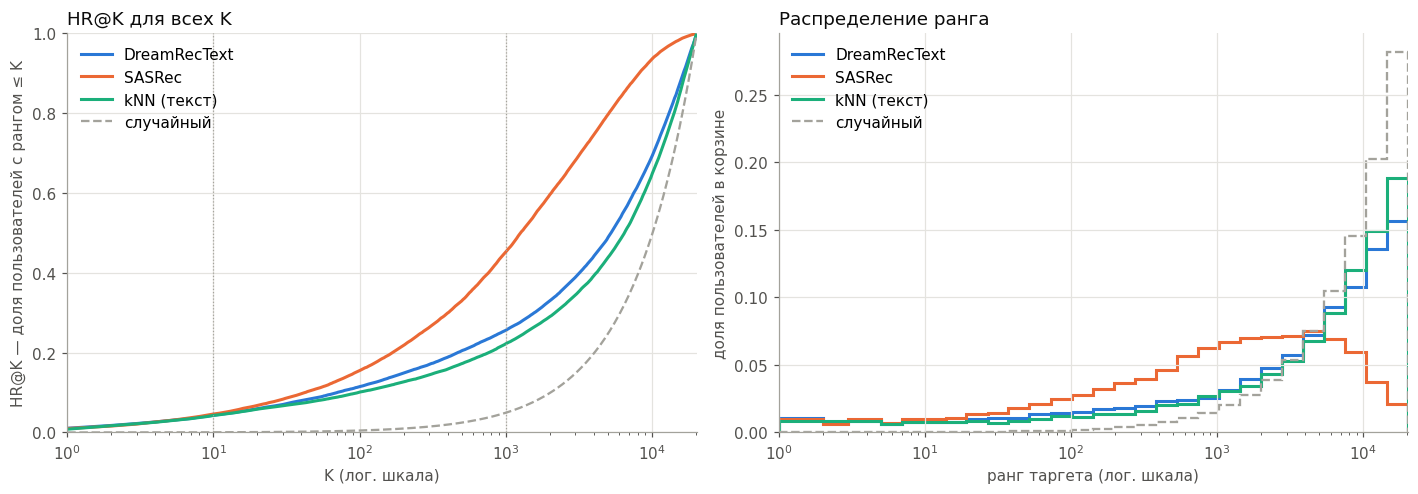

In [8]:
fig, (ax_cdf, ax_hist) = plt.subplots(1, 2, figsize=(13, 4.6))

# ── HR@K для всех K: эмпирическая функция распределения ранга ───────────
K = np.unique(np.logspace(0, np.log10(N_ITEMS), 400).astype(int))
for n, r in R1.items():
    hr = np.searchsorted(np.sort(r), K, side='right') / len(r)
    ax_cdf.plot(K, hr, lw=2, color=COLORS[n], label=n)
ax_cdf.plot(K, K / N_ITEMS, lw=1.5, ls='--', color=BASE, label='случайный')
for k in (10, 1000):
    ax_cdf.axvline(k, color=BASE, lw=0.8, ls=':')
ax_cdf.set_xscale('log')
ax_cdf.set_xlim(1, N_ITEMS)
ax_cdf.set_ylim(0, 1)
ax_cdf.set_xlabel('K (лог. шкала)')
ax_cdf.set_ylabel('HR@K — доля пользователей с рангом ≤ K')
ax_cdf.set_title('HR@K для всех K', loc='left', color=INK)
ax_cdf.legend(frameon=False, loc='upper left')

# ── Гистограмма ранга в логарифмических корзинах ────────────────────────
edges = np.unique(np.logspace(0, np.log10(N_ITEMS + 1), 31).astype(int))
for n, r in R1.items():
    share = np.histogram(r, bins=edges)[0] / len(r)
    ax_hist.stairs(share, edges, lw=2, color=COLORS[n], label=n)
ax_hist.stairs(np.diff(edges) / N_ITEMS, edges, lw=1.5, ls='--', color=BASE, label='случайный')
ax_hist.set_xscale('log')
ax_hist.set_xlim(1, N_ITEMS)
ax_hist.set_ylim(0, None)
ax_hist.set_xlabel('ранг таргета (лог. шкала)')
ax_hist.set_ylabel('доля пользователей в корзине')
ax_hist.set_title('Распределение ранга', loc='left', color=INK)
ax_hist.legend(frameon=False, loc='upper left')

fig.tight_layout()
plt.show()

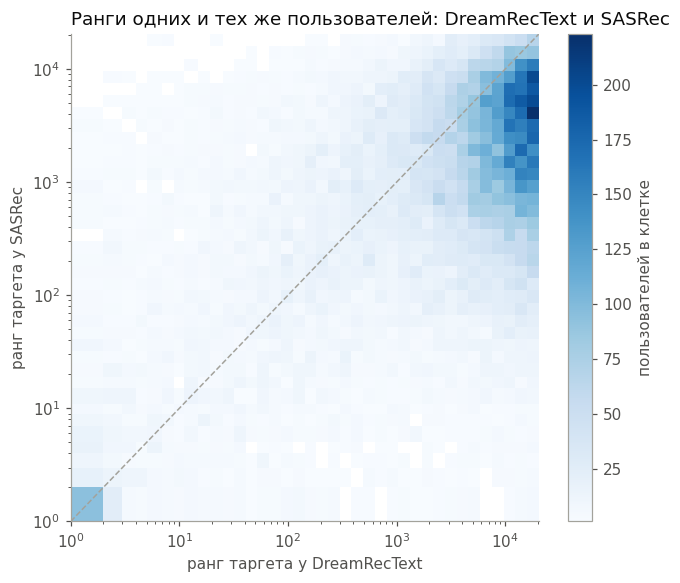

Корреляция Спирмена рангов: 0.369
DreamRecText ставит таргет выше, чем SASRec, у 28.8% пользователей, ниже — у 70.6%, одинаково — у 0.6%
  у кого SASRec дал ранг 1–10 (4.6%): медианный ранг у DreamRecText — 22
  у кого SASRec дал ранг 11–1000 (40.6%): медианный ранг у DreamRecText — 2982
  у кого SASRec дал ранг 1001–20259 (54.8%): медианный ранг у DreamRecText — 7402


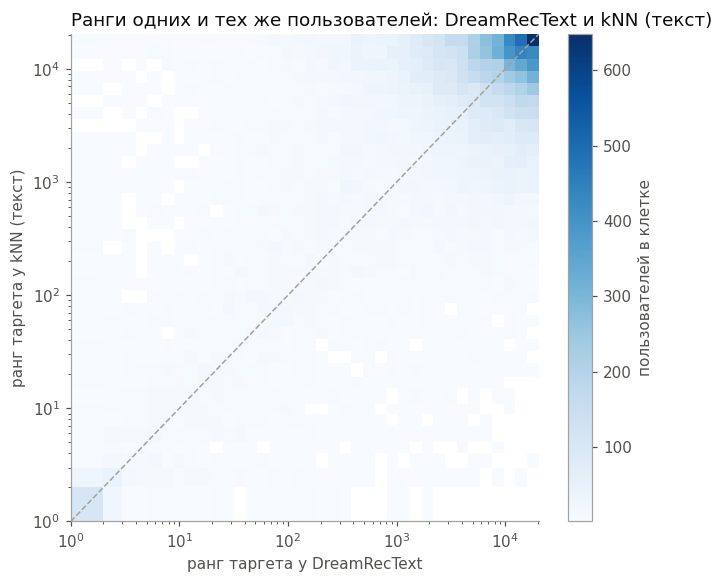

Корреляция Спирмена рангов: 0.444
DreamRecText ставит таргет выше, чем kNN (текст), у 53.5% пользователей, ниже — у 45.6%, одинаково — у 0.9%
  у кого kNN (текст) дал ранг 1–10 (4.3%): медианный ранг у DreamRecText — 8
  у кого kNN (текст) дал ранг 11–1000 (17.9%): медианный ранг у DreamRecText — 408
  у кого kNN (текст) дал ранг 1001–20259 (77.8%): медианный ранг у DreamRecText — 7167


In [9]:
from scipy.stats import spearmanr

# Границы корзин — целые: ранги целые, и в дробной лог-корзине между 1 и 10 может не оказаться ни одного
PAIR_EDGES = np.unique(np.logspace(0, np.log10(N_ITEMS + 1), 41).astype(int))


def paired(a: str, b: str) -> None:
    # ── Ранги одних и тех же пользователей у двух моделей ───────────────
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    _, _, _, img = ax.hist2d(R1[a], R1[b], bins=[PAIR_EDGES, PAIR_EDGES], cmap='Blues', cmin=1)
    ax.plot([1, N_ITEMS], [1, N_ITEMS], color=BASE, lw=1, ls='--')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(f'ранг таргета у {a}')
    ax.set_ylabel(f'ранг таргета у {b}')
    ax.set_title(f'Ранги одних и тех же пользователей: {a} и {b}', loc='left', color=INK)
    ax.grid(False)
    fig.colorbar(img, ax=ax, label='пользователей в клетке')
    fig.tight_layout()
    plt.show()

    print(f'Корреляция Спирмена рангов: {spearmanr(R1[a], R1[b]).statistic:.3f}')
    print(f'{a} ставит таргет выше, чем {b}, у {(R1[a] < R1[b]).mean():.1%} пользователей, '
          f'ниже — у {(R1[a] > R1[b]).mean():.1%}, одинаково — у {(R1[a] == R1[b]).mean():.1%}')
    for lo, hi in ((1, 10), (11, 1000), (1001, N_ITEMS)):
        m = (R1[b] >= lo) & (R1[b] <= hi)
        print(f'  у кого {b} дал ранг {lo}–{hi} ({m.mean():.1%}): медианный ранг у {a} — {np.median(R1[a][m]):.0f}')


for a, b in PAIRS:
    paired(a, b)

## Похож ли запрос модели на товары из истории

Гипотеза: oracle DreamRecText оказывается рядом с одним из товаров истории пользователя, и выдача —
это по сути соседи этого товара. Всё считается в пространстве и метрике, в которых модель делает
ретривал, и через **ранги**, а не сырые косинусы (в 1024-мерном пространстве после whitening они плохо
читаются). SASRec — контроль: то же для его вектора пользователя `h`.

1. **Лучший ранг товара из истории** в ранжировании по запросу. Контроль — история *случайного другого*
   пользователя той же длины: столько получилось бы случайно (популярные товары часто попадают в истории).
2. **Какой товар истории ближе всего** — его позиция с конца истории (1 — последний). Почти всегда
   последний — это «kNN по последнему товару»; разброс по истории — «выбирает один из товаров истории».
3. **К чему запрос ближе — к таргету или к истории**: доля пользователей, у которых какой-то товар истории
   стоит выше таргета, отдельно для попаданий и промахов; и ранг таргета среди текстовых соседей
   ближайшего к запросу товара истории — попадает ли модель тогда, когда таргет похож на этот товар.

**1. Лучший ранг товара из истории** (ранг с 1 из 20 259)

,медиана,= 1,≤ 10,≤ 100,top-1 выдачи — из истории,доля истории в top-10
DreamRecText,2,46.4%,91.1%,99.9%,46.3%,14.4%
DreamRecText — контроль: чужая история,850,0.6%,2.6%,12.0%,—,—
SASRec,5,23.8%,67.5%,96.3%,23.8%,12.5%
SASRec — контроль: чужая история,922,0.6%,3.6%,18.2%,—,—


**2. Позиция ближайшего к запросу товара истории** (с конца: 1 — последний)

,1,2,3,4,5,6+
DreamRecText,46.9%,6.6%,5.2%,5.0%,4.1%,32.2%
SASRec,26.6%,20.1%,12.9%,9.4%,7.2%,23.9%
если бы это был случайный товар истории,7.9%,7.9%,7.9%,7.9%,7.9%,60.4%


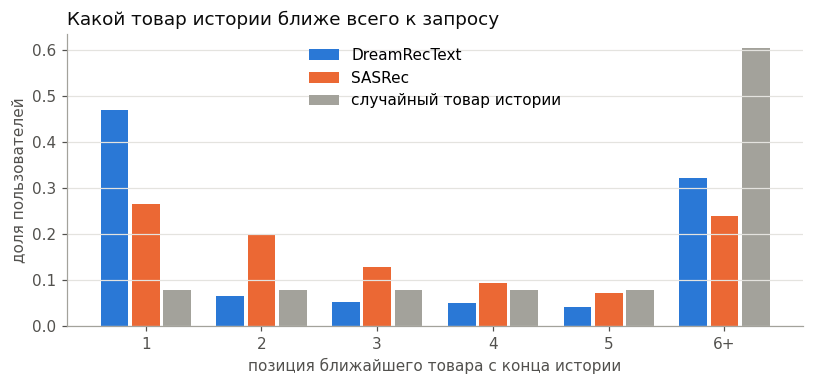

In [10]:
ANALYZED = ['DreamRecText', 'SASRec']           # чей запрос проверяем; SASRec — контроль

# Уникальные товары истории от последнего к первому: позиция 1 — последний купленный
HIST = [np.array(list(dict.fromkeys(reversed(list(s))))) for s in split_df['seq']]
LENS = np.array([len(h) for h in HIST])

# Контроль: история другого пользователя с тем же числом уникальных товаров
rng = np.random.default_rng(0)
ctrl = np.arange(len(HIST))
for L in np.unique(LENS):
    ids = rng.permutation(np.flatnonzero(LENS == L))
    ctrl[ids] = np.roll(ids, 1)                  # сдвиг по кругу: в группе из ≥ 2 никто не получит себя
HIST_CTRL = [HIST[j] for j in ctrl]


@torch.no_grad()
def item_ranks(name: str, items: list, batch: int = 256) -> list:
    # Ранг (с 1) каждого товара items[u] в ранжировании модели name для пользователя u
    m, W = models[name], item_table(models[name])
    out = []
    for s in range(0, len(items), batch):
        scores = scores_of(QUERY[name][s:s + batch].to(device), W, m['metric'])
        sorted_asc = scores.sort(dim=1).values
        chunk = items[s:s + batch]
        idx = torch.zeros(len(chunk), max(len(x) for x in chunk), dtype=torch.long)
        for i, x in enumerate(chunk):
            idx[i, :len(x)] = torch.from_numpy(x)
        v = scores.gather(1, idx.to(device)).contiguous()
        rank = (N_ITEMS - torch.searchsorted(sorted_asc, v, right=True) + 1).cpu().numpy()   # 1 + число строго выше
        out += [rank[i, :len(x)] for i, x in enumerate(chunk)]
    return out


HIST_RANK = {n: item_ranks(n, HIST) for n in ANALYZED}
BEST_HIST = {n: np.array([r.min() for r in HIST_RANK[n]]) for n in ANALYZED}

# ── 1. Лучший ранг товара из истории ────────────────────────────────────
rows = {}
for n in ANALYZED:
    best_ctrl = np.array([r.min() for r in item_ranks(n, HIST_CTRL)])
    for label, best in ((n, BEST_HIST[n]), (f'{n} — контроль: чужая история', best_ctrl)):
        rows[label] = {'медиана': np.median(best), '= 1': (best == 1).mean(),
                       '≤ 10': (best <= 10).mean(), '≤ 100': (best <= 100).mean()}
    seen = [set(h) for h in HIST]
    rows[n]['top-1 выдачи — из истории'] = np.mean([RECS[n][u, 0] in seen[u] for u in range(len(HIST))])
    rows[n][f'доля истории в top-{TOP_K}'] = np.mean([np.isin(RECS[n][u, :TOP_K], HIST[u]).mean()
                                                     for u in range(len(HIST))])
best_tab = pd.DataFrame(rows).T
display(Markdown('**1. Лучший ранг товара из истории** (ранг с 1 из 20 259)'))
display(best_tab.style.format({'медиана': '{:,.0f}', **{c: '{:.1%}' for c in best_tab if c != 'медиана'}},
                              na_rep='—'))

# ── 2. Позиция ближайшего к запросу товара истории (1 — последний) ───────
POS = {n: np.array([r.argmin() + 1 for r in HIST_RANK[n]]) for n in ANALYZED}
POS_BINS = ['1', '2', '3', '4', '5', '6+']


def pos_shares(pos: np.ndarray) -> list:
    return [(pos == k).mean() for k in range(1, 6)] + [(pos >= 6).mean()]


uniform_pos = [np.mean((LENS >= k) / LENS) for k in range(1, 6)] + [np.mean(np.maximum(LENS - 5, 0) / LENS)]
pos_tab = pd.DataFrame({**{n: pos_shares(POS[n]) for n in ANALYZED},
                        'если бы это был случайный товар истории': uniform_pos}, index=POS_BINS).T
display(Markdown('**2. Позиция ближайшего к запросу товара истории** (с конца: 1 — последний)'))
display(pos_tab.style.format('{:.1%}'))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(POS_BINS))
width = 0.27
series = [(n, pos_shares(POS[n]), COLORS[n]) for n in ANALYZED] + [('случайный товар истории', uniform_pos, BASE)]
for i, (label, vals, color) in enumerate(series):
    ax.bar(x + (i - 1) * width, vals, width=width - 0.03, color=color, label=label)
ax.set_xticks(x, POS_BINS)
ax.set_xlabel('позиция ближайшего товара с конца истории')
ax.set_ylabel('доля пользователей')
ax.set_title('Какой товар истории ближе всего к запросу', loc='left', color=INK)
ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Как читать примеры

* история — последние `HISTORY_SHOWN` товаров (снизу — самый поздний), в скобках популярность в train;
* таргет — следующий товар и его ранг у каждой модели;
* выдача — top-10 обеих моделей рядом: ✅ — таргет, 🔁 — товар уже есть в истории пользователя.

In [11]:
def user_header(u: int) -> str:
    # Markdown: последние HISTORY_SHOWN товаров истории и таргет с его рангом у каждой модели
    seq = list(split_df['seq'].iloc[u])
    tgt = TARGET[u]
    hist = seq[-HISTORY_SHOWN:]
    lines = [f'**Пользователь #{u}** — история {len(seq)} товаров'
             + (f', показаны последние {len(hist)}' if len(seq) > len(hist) else '')]
    lines += [f'{len(seq) - len(hist) + j + 1:>3}. {name_of(i)} (поп. {POP[i]})' for j, i in enumerate(hist)]
    ranks = ', '.join(f'{n}: ранг **{RANK[n][u]}**' for n in RECS)
    lines.append(f'\n**Таргет:** {name_of(tgt)} (поп. {POP[tgt]}) — {ranks}')
    return '  \n'.join(lines)


def item_cell(i: int, u: int) -> str:
    # Название товара в выдаче пользователя u: ✅ — таргет, 🔁 — уже есть в истории
    mark = '✅ ' if i == TARGET[u] else ('🔁 ' if i in set(split_df['seq'].iloc[u]) else '')
    return f'{mark}{name_of(i, 60)}'


def show(u: int) -> None:
    display(Markdown(user_header(u)))
    display(pd.DataFrame({n: [item_cell(i, u) for i in RECS[n][u, :TOP_K]] for n in RECS},
                         index=pd.RangeIndex(1, TOP_K + 1, name='#')))


def examples(mask: np.ndarray, title: str) -> None:
    pool = np.flatnonzero(mask)
    display(Markdown(f'### {title}\n{len(pool):,} пользователей ({len(pool) / len(mask):.1%})'))
    for u in np.random.default_rng(EXAMPLE_SEED).choice(pool, size=min(N_EXAMPLES, len(pool)), replace=False):
        show(int(u))

## Хорошие и плохие примеры для каждой модели

In [12]:
for n in RECS:
    examples(RANK[n] < TOP_K, f'{n}: хорошо — таргет в top-{TOP_K}')

### DreamRecText: хорошо — таргет в top-10
1,023 пользователей (4.3%)

**Пользователь #15513** — история 12 товаров, показаны последние 8  
  5. Funko Pop! Anime: Dragonball Z Piccolo Action Figure  [Funko] (поп. 24)  
  6. Funko Pop Animation: Dragonball Super - Goku Ultra Instinct Form Coll…  [Funko] (поп. 11)  
  7. Funko POP Marvel Dr. Strange Figure (9744)  [Funko] (поп. 26)  
  8. Funko POP! Marvel: Avengers Infinity War - Iron Man, Multicolor  [Funko] (поп. 38)  
  9. Funko Pop Disney: Beauty & The Beast - Belle Action Figure  [Funko] (поп. 15)  
 10. Funko POP Disney: Snow White - Snow White Collectible Vinyl Figure,Ye…  [Funko] (поп. 16)  
 11. Funko POP! Marvel: Avengers Infinity War - Iron Spider  [Funko] (поп. 39)  
 12. Funko Pop! Rides: Game of Thrones - Night King On Dragon Collectible …  [Funko] (поп. 14)  

**Таргет:** Funko Pop Rides: Game of Thrones - Dragon & Daenerys Action Figure  [Funko] (поп. 33) — DreamRecText: ранг **0**, SASRec: ранг **37**, kNN (текст): ранг **1**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,✅ Funko Pop Rides: Game of Thrones - Dragon & Daenerys Action… [Funko],Funko POP Movies: Guardians of The Galaxy 2 Star Lord Toy F… [Funko],🔁 Funko Pop! Rides: Game of Thrones - Night King On Dragon Co… [Funko]
2,Funko POP Game of Thrones: Night King Action Figure [Funko],"🔁 Funko POP! Marvel: Avengers Infinity War - Iron Man, Multic… [Funko]",✅ Funko Pop Rides: Game of Thrones - Dragon & Daenerys Action… [Funko]
3,Funko POP! TV: Game of Thrones - Daenerys (White Coat) [Funko],Funko Movies: Thor Ragnarok-Pop 12 Collectible Figure [Funko],Funko POP Game of Thrones: Night King Action Figure [Funko]
4,Funko POP! Game of Thrones Brienne of Tarth Vinyl Figure [Funko],Guardians of The Galaxy Vol. 2 Rocket Pop! Vinyl Figure [Funko],Funko POP Game of Thrones: Jaime Lannister Vinyl Figure [Funko]
5,Funko Pop! TV: Game of Thrones - Arya with Two Headed Spear… [Funko],Funko Pop! Movie Moment: Batman 80th - Batman with Light Up… [Funko],Funko POP! Game of Thrones Drogon Vinyl Figure [Funko]
6,🔁 Funko Pop! Rides: Game of Thrones - Night King On Dragon Co… [Funko],🔁 Funko Pop! Rides: Game of Thrones - Night King On Dragon Co… [Funko],Funko POP Game of Thrones: Arya Stark Vinyl Figure [Funko]
7,Funko POP Game of Thrones: Daenerys Targaryen Vinyl Figure … [Funko],"Funko Pop! Marvel: Avengers Infinity War 6"" Hulk Buster Fig… [Funko]",Funko POP Game of Thrones: Daenerys Targaryen Vinyl Figure … [Funko]
8,Funko POP! Game of Thrones Tyrion Battle Axe Vinyl Figure [Funko],"Funko Marvel Collector Corps, Subscription Box, Venom Theme… [Funko]",Funko POP Game of Thrones: Cersei Lannister Vinyl Figure [Funko]
9,Funko POP Game of Thrones: Ned Stark Vinyl Figure [Funko],🔁 Funko POP Disney: Snow White - Snow White Collectible Vinyl… [Funko],"Funko POP Game of Thrones: Viserion 6"" Action Figure [Funko]"


**Пользователь #11655** — история 12 товаров, показаны последние 8  
  5. Green Toys Helicopter, Blue/Green  [Green Toys] (поп. 73)  
  6. Step2 Extreme Coaster for Kids - Roller Coaster for Toddlers - Slide …  [Step2] (поп. 11)  
  7. Green Toys Tractor Vehicle, Orange  [Green Toys] (поп. 78)  
  8. K'NEX 70 Model Building Set - 705 Pieces - Ages 7+ Engineering Educat…  [K'NEX] (поп. 39)  
  9. Gymnic Rody Bounce Horse Dark Brown  [GYMNIC] (поп. 47)  
 10. Fun Central 12-Pack Realistic Rubber Snakes - 14-Inch Flexible Prank …  [Fun Central] (поп. 8)  
 11. 25 Rare Pokemon Cards with 100 HP or Higher (Assorted Lot with No Dup…  [Pokemon] (поп. 45)  
 12. Pokemon TCG: Random Cards from Every Series, 50 Cards in Each Lot  [Pokemon] (поп. 50)  

**Таргет:** Pokemon Random Reverse Foil Single Cards, Lot of 25  [Pokemon] (поп. 32) — DreamRecText: ранг **3**, SASRec: ранг **121**, kNN (текст): ранг **6**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"🔁 Pokemon TCG: Random Cards from Every Series, 50 Cards in Ea… [Pokemon]","🔁 Aurora World 11"" Pinky The Pig [Aurora World]","🔁 Pokemon TCG: Random Cards from Every Series, 50 Cards in Ea… [Pokemon]"
2,"Pokemon TCG: Random Cards from Every Series, 100 Cards in E… [Pokemon]",ThinkFun Zingo Sight Words Award Winning Early Reading Game… [Think Fun],"Pokemon TCG: Random Cards from Every Series, 100 Cards in E… [Pokemon]"
3,"Pokemon TCG: Random Cards From Every Series, 100 Cards In E… [Pokemon]","Aurora - Miyoni - 10"" German Shepherd [Aurora World]","Pokemon TCG: Random Cards From Every Series, 100 Cards In E… [Pokemon]"
4,"✅ Pokemon Random Reverse Foil Single Cards, Lot of 25 [Pokemon]","Jenga Classic Game with Genuine Hardwood Blocks, Stacking T… [Hasbro Gaming]",50 Pokemon Energy Cards Random Lot of Cards [Nintendo]
5,🔁 25 Rare Pokemon Cards with 100 HP or Higher (Assorted Lot w… [Pokemon],Ultra Pro Silver Series 9 Pocket Pages (25 count pack) [Ultra Pro],Cazillion Cards Pokemon Cards 50 Card Assorted Lot (Commons… [Pokemon]
6,Pokémon Rare Grab Bag 20 Rare Pokémon Cards [Pokemon],"🔁 Pokemon TCG: Random Cards from Every Series, 50 Cards in Ea… [Pokemon]",Pokémon Rare Grab Bag 20 Rare Pokémon Cards [Pokemon]
7,25 Rare Pokemon Cards with 100 HP or Higher (Assorted Lot w… [Top Cut Central],"Prank Pack, Plant Urinal Prank Gift Box, Wrap Your Real Pre… [Prank Pack]","✅ Pokemon Random Reverse Foil Single Cards, Lot of 25 [Pokemon]"
8,50 Pokemon Energy Cards Random Lot of Cards [Nintendo],"Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strate… [Hasbro Gaming]",🔁 25 Rare Pokemon Cards with 100 HP or Higher (Assorted Lot w… [Pokemon]
9,Ultra Pro UP-84237 -Pokemon- X and Y 2 3-Ring Binder [Ultra Pro],🔁 25 Rare Pokemon Cards with 100 HP or Higher (Assorted Lot w… [Pokemon],25 Rare Pokemon Cards with 100 HP or Higher (Assorted Lot w… [Top Cut Central]


**Пользователь #20559** — история 12 товаров, показаны последние 8  
  5. Green Toys Ferry Boat with Mini Cars Bathtub Toy, Blue/White, Standard  [Green Toys] (поп. 203)  
  6. Green Toys, Tugboat , Blue  [Green Toys] (поп. 32)  
  7. Green Toys Dumper Vehicle  [Green Toys] (поп. 14)  
  8. Green Toys Scooper Construction Truck, Yellow/Orange  [Green Toys] (поп. 42)  
  9. Green Toys Recycling Truck in Green Color - BPA and Phthalates Free G…  [Green Toys] (поп. 68)  
 10. Green Toys Dump Truck in Yellow and Red - BPA Free, Phthalates Free T…  [Green Toys] (поп. 105)  
 11. Backyard Safari Magnifying Glass  [Backyard Safari] (поп. 23)  
 12. Kidwinz Original Compact 8x21 Kids Binoculars Set - High Resolution R…  [Kidwinz] (поп. 16)  

**Таргет:** Green Toys Car Carrier, Blue - Pretend Play, Motor Skills, Kids Toy V…  [Green Toys] (поп. 89) — DreamRecText: ранг **7**, SASRec: ранг **1**, kNN (текст): ранг **3711**

... (11 outputs left out)

**Пользователь #11700** — история 10 товаров, показаны последние 8  
  3. Funko POP Movies: Harry Potter - Severus Snape Action Figure, Multico…  [Funko] (поп. 38)  
  4. Funko Pop! Disney: Incredibles 2 - Violet (Styles May Vary) Collectib…  [Funko] (поп. 16)  
  5. Funko POP! Marvel: Marvel Comics Gwenom Collectible Figure, Multicolor  [Funko] (поп. 13)  
  6. Funko Pop Disney: Mulan - Mulan (New) Collectible Vinyl Figure  [Funko] (поп. 12)  
  7. Funko Disney Mulan Pop Vinyl Figure,Multi  [Funko] (поп. 14)  
  8. Funko POP Movies: Harry Potter Action Figure  [Funko] (поп. 51)  
  9. Funko POP! Animation: My Hero Academia - Tsuyu Collectible Figure, Mu…  [Funko] (поп. 11)  
 10. Funko Pop Anime One Punch Man-Saitama Toy  [Funko] (поп. 8)  

**Таргет:** Funko POP Anime: Naruto Shippuden Kakashi Toy Figure, Gray  [Funko] (поп. 12) — DreamRecText: ранг **7**, SASRec: ранг **43**, kNN (текст): ранг **3**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,🔁 Funko Pop Anime One Punch Man-Saitama Toy [Funko],Funko Pop! Movie Moment: Batman 80th - Batman with Light Up… [Funko],🔁 Funko Pop Anime One Punch Man-Saitama Toy [Funko]
2,🔁 Funko POP! Animation: My Hero Academia - Tsuyu Collectible … [Funko],Funko POP Movies: Guardians of The Galaxy 2 Toddler Groot T… [Funko],"Funko POP Anime: Naruto Sasuke Action Figure Multi, Standard [Funko]"
3,Funko POP! Anime: My Hero Academia - Katsuki Bakugo [Funko],Funko Pop Disney: Lilo & Stitch Seated Action Figure [Funko],Funko 7POP Amazon Exclusive Action Figure [Funko]
4,"Funko POP Anime: Naruto Sasuke Action Figure Multi, Standard [Funko]","Funko Star Wars: The Mandalorian - Covert Mandalorian, Mult… [Funko]","✅ Funko POP Anime: Naruto Shippuden Kakashi Toy Figure, Gray [Funko]"
5,Funko POP Rocks: Slash Action Figure [Funko],"Funko POP! Marvel: Avengers Infinity War - Iron Man, Multic… [Funko]",Funko POP Anime: Bleach Ichigo Action Figure [Funko]
6,Funko Harry Potter Professor McGonagall Pop Figure [Funko],Funko POP! Marvel: Avengers Infinity War - Thanos [Funko],Funko POP Games: Mega Man - Mega Man Action Figure [Funko]
7,Funko POP Anime: Bleach Ichigo Action Figure [Funko],🔁 Funko POP! Animation: My Hero Academia - Tsuyu Collectible … [Funko],Funko Pop Television TMNT Donatello Vinyl Figure [Funko]
8,"✅ Funko POP Anime: Naruto Shippuden Kakashi Toy Figure, Gray [Funko]",🔁 Funko POP Movies: Harry Potter Action Figure [Funko],Funko Frozen Pocket Pop! Mini Vinyl Figure Tin (3-Pack) [Funko]
9,Funko POP! Disney: Moana - Te Fiti [Funko],Funko POP Rocks: Slash Action Figure [Funko],Funko POP Television TMNT Splinter Vinyl Figure [Funko]


**Пользователь #20150** — история 11 товаров, показаны последние 8  
  4. 5 LIVE Caterpillars - Cup of Caterpillars - Butterfly Kit Refill - Sh…  [Insect Lore] (поп. 32)  
  5. Melissa & Doug Design-Your-Own Headbands Jewelry-Making Kit With 50+ …  [Melissa & Doug] (поп. 20)  
  6. Mattel Disney Frozen Fever Anna Doll  [Mattel] (поп. 35)  
  7. Disney Descendants Signature Mal Isle of the Lost Doll  [Disney Descendants] (поп. 24)  
  8. Mattel Monster High Boo York, Boo York City Schemes Nefera de Nile Do…  [Mattel] (поп. 46)  
  9. Kinetic Sand Doggy Daycare Playset  [Kinetic Sand] (поп. 11)  
 10. Paw Patrol Racers 3-Pack Vehicle Set, Rescue Marshall, Spy Chase, and…  [Paw Patrol] (поп. 39)  
 11. Schleich 14710 White-Tailed Doe Toy Figure, Multicolor  [Schleich] (поп. 15)  

**Таргет:** Schleich White-Tailed Fawn Toy Figure  [Schleich] (поп. 27) — DreamRecText: ранг **0**, SASRec: ранг **0**, kNN (текст): ранг **1**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,✅ Schleich White-Tailed Fawn Toy Figure [Schleich],✅ Schleich White-Tailed Fawn Toy Figure [Schleich],"🔁 Schleich 14710 White-Tailed Doe Toy Figure, Multicolor [Schleich]"
2,"🔁 Schleich 14710 White-Tailed Doe Toy Figure, Multicolor [Schleich]","🔁 Schleich 14710 White-Tailed Doe Toy Figure, Multicolor [Schleich]",✅ Schleich White-Tailed Fawn Toy Figure [Schleich]
3,"Schleich Wild Life, Animal Figurine, Animal Toys for Boys a… [Schleich]","Schleich bayala, Unicorn Toys for Girls and Boys, Rainbow U… [Schleich]",Terra by Battat – North American Animals Set – Realistic An… [TERRA BY BATTAT]
4,SCHLEICH Chick [Schleich],"Schleich Farm World, Horse Toys for Girls and Boys Ages 3 a… [Schleich]","Schleich Wild Life, Animal Figurine, Animal Toys for Boys a… [Schleich]"
5,"Schleich Horse Club, Realistic Horse Toys for Girls and Boy… [Schleich]",Nuby Octopus 100% Silicone Pull String Interactive Toy: 18M… [Nuby],"Schleich Wild Life, Animal Figurine, Animal Toys for Boys a… [Schleich]"
6,"Schleich Wild Life, Animal Figurine, Animal Toys for Boys a… [Schleich]",Melissa & Doug Jumbo Coloring Pad: Vehicles - 50 Pages of W… [Melissa & Doug],Terra by Battat – Zebra Family – Miniature Zebra Animal Toy… [B.]
7,"Schleich Wild Life, Animal Figurine, Animal Toys for Boys a… [Schleich]",SwimWays Swirl Divers Kids Fish-Shaped Pool Diving Toys (2 … [SwimWays],Rhode Island Novelty Tyrannosaurus Rex 9 Inch Tall Plush T-… [Rhode Island Novelty]
8,Schleich Carnotaurus [Schleich],"Schleich Wild Life, Realistic Wild Animal Toy For Boys and … [Schleich]",ENCHANTIMALS COZY DEER HOUSE PLAYSET + DANESSA DEER DOLL & … [Mattel]
9,"Schleich Wild Life, Animal Figurine, Animal Toys for Boys a… [Schleich]","Schleich Farm World, Animal Figurine, Farm Toys for Boys an… [Schleich]","Youtooz Oh Deer Plush Plush 9"" in, Huggable Soft and Cute D… [You Tooz]"


In [13]:
for n in RECS:
    examples(RANK[n] >= BAD_RANK, f'{n}: плохо — ранг таргета ≥ {BAD_RANK}')

### DreamRecText: плохо — ранг таргета ≥ 1000
17,748 пользователей (74.4%)

**Пользователь #15141** — история 19 товаров, показаны последние 8  
 12. LEGO Education Doors, Windows, & Roof Tiles Accessory Toy Set 9386 fo…  [LEGO] (поп. 9)  
 13. Melissa & Doug Scratch Art Friendship Mini Notes (125) With Wooden St…  [Melissa & Doug] (поп. 107)  
 14. Fisher-Price Disney Minnie, Rainbow Dazzle Minnie  [Fisher-Price] (поп. 19)  
 15. WikkiStix Fun Paks, Contains 50 Individual paks! Great for Parties, T…  [WikkiStix] (поп. 12)  
 16. Mattel Games Gas Out for Kids, Family & Game Night, Hilarious Electro…  [Mattel Games] (поп. 20)  
 17. Money Gift Boxes for Cash, Money Puzzle Box for Cash Gift, Money Gift…  [AGREATLIFE] (поп. 32)  
 18. Lightning Reaction Reloaded - Shocking Game  [Paladone] (поп. 18)  
 19. Boom Boom Balloon, Exciting Anticipation Family Board Game Outdoor Su…  [Spin Master Games] (поп. 32)  

**Таргет:** Prank Pack, Plant Urinal Prank Gift Box, Wrap Your Real Present in a …  [Prank Pack] (поп. 30) — DreamRecText: ранг **7632**, SASRec: ранг **3893**, kNN (текст): ранг **9678**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strate… [Hasbro Gaming]",Exploding Kittens Party Pack Card Game by Exploding kittens… [Exploding Kittens LLC],"🔁 Boom Boom Balloon, Exciting Anticipation Family Board Game … [Spin Master Games]"
2,"Barbie Made to Move Doll, Orange Top [Barbie]","Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strate… [Hasbro Gaming]","Bean Bag Toss Game for Kids, Foldable Kids Cornhole Outdoor… [Kidstella]"
3,"🔁 Boom Boom Balloon, Exciting Anticipation Family Board Game … [Spin Master Games]",Melissa & Doug Suspend Family Game (31 pcs) - Wire Balance … [Melissa & Doug],Melissa & Doug Junior Suspend Family Game (31 pcs) [Melissa & Doug]
4,"Connect 4 Spin Game, Features Spinning Connect 4 Grid, 2 Pl… [Hasbro Gaming]","Wonder Forge Richard Scarry's Busytown, Eye Found It Toddle… [Ravensburger]",B. Toys – Bean Bag Toss Game – 3 Games & 8 Bean Bags – Fun … [B. toys]
5,"Mattel Games UNO: Classic Card Game, Multi, 8 x 3-3/4 x 81/… [Mattel Games]","Aurora World Flopsie Drake Dolphin 12"" [Aurora Plush]","Adult Party Games, Fun Twister Game Night for Group and Fam… [HAPTIME]"
6,🔁 HABA Half Dozen Wooden Eggs in Real Egg Carton Realistic Pl… [HABA],Mattel Games Blokus Game [Mattel Games],"Connect 4 Spin Game, Features Spinning Connect 4 Grid, 2 Pl… [Hasbro Gaming]"
7,"Biulotter 72PCS Easter Eggs, Colorful Bright Plastic Easter… [Biulotter]",Ticket to Ride Board Game | Family Board Game | Board Game … [Days of Wonder],"Hasbro Gaming Bulls-Eye Ball Game for Kids Ages 8 and Up, A… [Hasbro Gaming]"
8,Melissa & Doug Play-Time Produce Fruit (9 pcs) and Vegetabl… [Melissa & Doug],Hasbro Gaming: Battleship Classic Board Game Strategy Game … [Hasbro Gaming],Playz 5-in-1 Rocket Ship Play Tent for Kids with Dart Board… [Playz]
9,Connect 4 Strategy Board Game for Ages 6 and Up (Amazon Exc… [Hasbro Gaming],"Bounce Off Game with Bouncing Pattern Challenges, for Famil… [Mattel Games]","20 Rocket Balloons with Pump,(Colors May Vary),Various Pack… [Toysmith]"


**Пользователь #12188** — история 10 товаров, показаны последние 8  
  3. Little Tikes Big Digger Sandbox, White  [Little Tikes] (поп. 26)  
  4. Create-A-Scene — Train Magnetic Playset — Portable Mess-Free Magnet A…  [PlayMonster] (поп. 9)  
  5. MAGNETIC FUN - MICKEY MOUSE MAGNETIC ZOO  [Disney] (поп. 13)  
  6. Briarpatch Travel Scavenger Hunt Card Game for Kids, Activities for F…  [Briarpatch] (поп. 40)  
  7. John Deere Radio Controlled Johnny Tractor Toy - John Deere Tractor T…  [John Deere] (поп. 9)  
  8. Intex Floating Hoops Basketball Game Colors May Vary  [Intex] (поп. 21)  
  9. K'NEX Imagine - Click & Construct Value Building Set - 522Piece - 35 …  [K'NEX] (поп. 9)  
 10. Pete the Cat Missing Cupcakes Board Game from Briarpatch, Create a Be…  [Briarpatch] (поп. 19)  

**Таргет:** Nickelodeon Paw Patrol Pop Up Game  [Nickelodeon] (поп. 17) — DreamRecText: ранг **9730**, SASRec: ранг **2230**, kNN (текст): ранг **166**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"🔁 Pete the Cat Missing Cupcakes Board Game from Briarpatch, C… [Briarpatch]",ThinkFun Zingo Sight Words Award Winning Early Reading Game… [Think Fun],"🔁 Pete the Cat Missing Cupcakes Board Game from Briarpatch, C… [Briarpatch]"
2,"Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strate… [Hasbro Gaming]",PicassoTiles 100 Piece Set 100pcs Magnet Building Tiles Cle… [PicassoTiles],"Briarpatch | Pete the Cat Groovy Buttons Game, Ages 3+ [Briarpatch]"
3,"MerryMakers Pete the Cat Plush Doll, 14.5-Inch , Blue [MerryMakers]","Kinetic Sand, Beach Day Fun Playset with Castle Molds, Tool… [Kinetic Sand]",Briarpatch | Let's Feed The Very Hungry Caterpillar Countin… [Briarpatch]
4,Educational Insights Pete The Cat I Love My White Shoes Gam… [Educational Insights],"Aurora - Mini Flopsie - 8"" Caramel Horse [Aurora World]",Educational Insights Pete The Cat I Love My Buttons Board G… [Educational Insights]
5,"Melissa & Doug Water Wow 4 Pack (Pets, Colors, Fairy Tale a… [Melissa & Doug]","Mattel Games UNO NFL LVII Card Game for Kids, Adults, Famil… [Mattel Games]",Educational Insights Pete The Cat I Love My White Shoes Gam… [Educational Insights]
6,"Educational Insights The Sneaky, Snacky Squirrel Game, 4 pl… [Educational Insights]","Don't Break the Ice Game, Multicolor [Hasbro Gaming]",Paw Patrol Mission Paw - Mission Pup Pad [Paw Patrol]
7,"Briarpatch | Pete the Cat Groovy Buttons Game, Ages 3+ [Briarpatch]","FUNZBO 500+ Snap Pop Beads - Beads for Jewelry Making Kit, … [FUNZBO]","MerryMakers Pete the Cat Plush Doll, 14.5-Inch , Blue [MerryMakers]"
8,"Barbie Made to Move Doll, Orange Top [Barbie]","Made By Me Create Your Own Holiday Window Art, Christmas Or… [Made By Me]",SweetAce Cat Toys for Kids 41 Pcs Cat Figures Playset Cat F… [SweetAce]
9,Ticket to Ride Board Game | Family Board Game | Board Game … [Days of Wonder],LEGO Classic Blue Baseplate 10714 Building Kit (1 Piece) [LEGO],Gift Item Paw Patrol Foam Floor Puzzle by Cardinal (25 Piec… [Paw Patrol]


**Пользователь #20255** — история 11 товаров, показаны последние 8  
  4. Play-Doh Bulk Winter Colors 12-Pack of Non-Toxic Modeling Compound, 4…  [Play-Doh] (поп. 30)  
  5. Melissa & Doug Reusable Puffy Sticker Wild Adventures Bundle: Safari,…  [Melissa & Doug] (поп. 12)  
  6. Learning Resources Mental Blox Critical Thinking Game, Homeschool, 20…  [Learning Resources] (поп. 53)  
  7. HahaGift Boys Toys Age 2-5, Animal Stacking Toys Wooden Blocks for Ki…  [HahaGift] (поп. 10)  
  8. Sushi Go! - The Pick and Pass Card Game  [Gamewright] (поп. 118)  
  9. Melissa & Doug Puffy Sticker Play Set 3-Pack (Pirates, Vehicles, Safa…  [Melissa & Doug] (поп. 21)  
 10. ZITA ELEMENT 24 Pcs 18 Inch Girl Doll Clothes and Accessories - Doll …  [ZITA ELEMENT] (поп. 11)  
 11. Educational Insights Kanoodle Extreme Classroom Pack of 10, Featuring…  [Educational Insights] (поп. 12)  

**Таргет:** Taco Cat Goat Cheese Pizza  [Taco Cat Goat Cheese Pizza] (поп. 44) — DreamRecText: ранг **4995**, SASRec: ранг **2**, kNN (текст): ранг **2939**

... (11 outputs left out)

**Пользователь #12270** — история 32 товаров, показаны последние 8  
 25. Light Up Bath Toys for Toddlers Kids Baby Boys, No Hole Dinosaur Bath…  [TSDATOWR] (поп. 10)  
 26. POSIKEDE Happy Traffic Foam Play Mat with Carpet Surface, 4FT x 6FT E…  [POSIKEDE] (поп. 10)  
 27. POSIKEDE Carpet Surface Foam Play Mat with Animal Pattern, 4FT x 6FT …  [POSIKEDE] (поп. 10)  
 28. TCG Toys Gelli Mat - Neutral Fun Alphabet Bathtub Knee Rest - Provide…  [TCG Toys] (поп. 17)  
 29. Attatoy Igloo Fort Play Tent Cover: Fort Building Kit Accessory  [Attatoy] (поп. 16)  
 30. 68 PCS Farm Animal Party Decorations, Farm Theme Birthday Party Table…  [ONCTTOS] (поп. 10)  
 31. Farm Party Decorations, 95 PCS Farm Animal Birthday Party Supplies In…  [ONCTTOS] (поп. 16)  
 32. LKyoxs Montessori Toys for 1 2 3 Year Old Toddlers Wooden Sorting & S…  [LKyoxs] (поп. 11)  

**Таргет:** Colorful Ball Pit Balls 100 Pink Ocean Balls for Babies Ball Pit Kids…  [BBRUN] (поп. 10) — DreamRecText: ранг **2136**, SASRec: ранг **522**, kNN (текст): ранг **14467**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,🔁 LKyoxs Montessori Toys for 1 2 3 Year Old Toddlers Wooden S… [LKyoxs],Wdebay 4 PCS Inertia Animal Car Toys for 1 Year Old Boy and… [Wdebay],🔁 LKyoxs Montessori Toys for 1 2 3 Year Old Toddlers Wooden S… [LKyoxs]
2,Wooden Blocks for Toddlers 1-3 Years Old Baby Boys Girls St… [HONGTEYA],UCIDCI Kids Smart Phone Toys for Boys Ages 3-7 with Learnin… [UCIDCI],Wooden Blocks for Toddlers 1-3 Years Old Baby Boys Girls St… [HONGTEYA]
3,Dreampark Montessori Toys for 1 2 Year Old - Toddler Wooden… [Dreampark],ALASOU Transparent Forest Car Toys for 1 2 3 Year Old Boy|T… [ALASOU],Dreampark Montessori Toys for 1 2 Year Old - Toddler Wooden… [Dreampark]
4,"kecristv Montessori Toys for 1 2 Year Old Boy and Girl, Woo… [kecristv]","Bubble Lawn Mower for Kids Toddlers,Automatic Push Toys,Sum… [Wesfuner]","EDUJOY Montessori Toys for 1 Year Old Boy Gifts, Shape Sort… [EDUJOY]"
5,Montessori Toys Baby Toddler Gifts: Wooden Sorting Stacking… [HEZEIYIX],"Ocestar Inflatable Pool Float Chair, 3 Pack Pool Float Adul… [Ocestar]","kecristv Montessori Toys for 1 2 Year Old Boy and Girl, Woo… [kecristv]"
6,"Montessori Toys for 1 2 3 Year Old Boys Girls Toddlers, Woo… [Zartores]","FUN LITTLE TOYS 6PCS 12"" Dinosaur Bath Toys, Saft Dinosaur … [FUN LITTLE TOYS]",SHARKWOODS Montessori Toys for 1 2 3 Years Old Boys Wooden … [SHARKWOODS]
7,"EDUJOY Montessori Toys for 1 Year Old Boy Gifts, Shape Sort… [EDUJOY]","kecristv Montessori Toys for 1 2 Year Old Boy and Girl, Woo… [kecristv]","Montessori Toys for 1 2 3 Year Old Boys Girls Toddlers, Woo… [Zartores]"
8,SHARKWOODS Montessori Toys for 1 2 3 Years Old Boys Wooden … [SHARKWOODS],"Ben and Bro Dinosaur Toys for Kids 3-5 6 7 8 Years Old, Tak… [Ben & Bro]",Montessori Toys Baby Toddler Gifts: Wooden Sorting Stacking… [HEZEIYIX]
9,40 Pcs Wooden Stacking Rocks - Choke-Free - Montessori Toys… [Reifier],🔁 LKyoxs Montessori Toys for 1 2 3 Year Old Toddlers Wooden S… [LKyoxs],"Bravmate Montessori Toys for 1 2 3 Year Old, Wooden Sorting… [Bravmate]"


**Пользователь #20289** — история 12 товаров, показаны последние 8  
  5. Sharper Image Bulldog Buggy RC Off-Road Race Car, Long-Lasting Rechar…  [SHARPER IMAGE] (поп. 36)  
  6. BaLaM Hover Soccer Ball Toys for 3-8 Year Old Kids Toddler Boys Girls…  [BaLaM] (поп. 10)  
  7. Gang Beasts Super Stretchy Plush - Yellow Chicken - 16 Inches - Cute …  [P.M.I.] (поп. 14)  
  8. CCG Select | Brilliant Box | 2 Booster Packs + 2 Ultra Rare | Fully C…  [CCG Select] (поп. 12)  
  9. CCG Select | Power Pack | 50+ Cards | 4 Holos or Rares | 1 Ultra Rare…  [CCG Select] (поп. 12)  
 10. GobiDex Gemstones Dig Kit, Solar System Science Kit for Kids, Excavat…  [GobiDex] (поп. 13)  
 11. Gang Beasts Action Figures Ultimate Collectors Set – 5 Figures – 6.5 …  [P.M.I.] (поп. 10)  
 12. Tangle Jr. Masterpiece 3-Pack Porcelain,Mache,Lollipop Artistic Patte…  [TANGLE] (поп. 12)  

**Таргет:** T.V.V.Fashy Quadair Helicopter Drone for Kids, Indoor RC Drones for K…  [T.V.V.Fashy] (поп. 5) — DreamRecText: ранг **10895**, SASRec: ранг **1689**, kNN (текст): ранг **11448**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"🔁 Tangle Jr. Masterpiece 3-Pack Porcelain,Mache,Lollipop Arti… [TANGLE]","🔁 Tangle Jr. Masterpiece 3-Pack Porcelain,Mache,Lollipop Arti… [TANGLE]","🔁 Tangle Jr. Masterpiece 3-Pack Porcelain,Mache,Lollipop Arti… [TANGLE]"
2,"Barbie Made to Move Doll, Orange Top [Barbie]","TECH DECK, Plan B Pro Series Finger Board with Storage Disp… [TECH DECK]","Tangle Jr. Masterpiece (3-Pack) - Maple, Splash, Stria Arti… [TANGLE]"
3,"Tangle Jr. Masterpiece (3-Pack) - Maple, Splash, Stria Arti… [TANGLE]","Ultra Pro 3"" X 4"" Ultra Clear Platinum Toploader 25ct for P… [Ultra Pro]",Tangle Jr. Fuzzies - Fuzzy Fidget Toy - Fuzzy Tangle Toy - … [TANGLE]
4,Tangle Palm Metallic 2-Pack Aqua Blue and Plum Purple - Big… [TANGLE],"Bakugan Legends, Baku-tin, Gargonoid X Webam (Exclusive, My… [Bakugan]",Tangle Palm Metallic 2-Pack Aqua Blue and Plum Purple - Big… [TANGLE]
5,"Snuggie Buggies Stuffed Animal Bear in a Lion Costume, Ultr… [Snuggie Buggies]",Trading Card Case Envelope Compatible for Pokemon Single Pa… [EVORETRO],TANGLE Set of 3 Jr. Original Fidget Toy [TANGLE]
6,Tangle Jr. Fuzzies - Fuzzy Fidget Toy - Fuzzy Tangle Toy - … [TANGLE],"Tangle Jr. Masterpiece (3-Pack) - Maple, Splash, Stria Arti… [TANGLE]",TANGLE Jr. Classics - Set of 3 Classic Jr. Fidget Toys [TANGLE]
7,Tangle Palm Classic 2-Pack Orange and Pink - Big Tangle for… [TANGLE],"Snuggie Buggies Stuffed Animal Bear in a Lion Costume, Ultr… [Snuggie Buggies]",Tangle Palm Classic 2-Pack Orange and Pink - Big Tangle for… [TANGLE]
8,"Daniel Tiger's Neighborhood Friends Figures Set, Multicolor… [Daniel Tiger's Neighbor...","Gabby’s Dollhouse, Purr-ific Pool Playset with Gabby and Me… [Gabby's Dollhouse]","PopSockets Fidget Train with Expanding PopSockets , Premium… [PopSockets]"
9,Daniel Tiger's Neighborhood Friends & Family Figure Set (10… [Daniel Tiger's Neighbor...,Chess Armory Premium Checkers and Chess Set - Wooden Board … [Chess Armory],"8 Pack Funny Sensory Fidget Toys, DIY Deformable Robot Fing… [Arlkono]"


## Где модели расходятся

In [14]:
for A, B in PAIRS:
    examples((RANK[A] < TOP_K) & (RANK[B] >= BAD_RANK), f'{A} угадал, {B} — ранг ≥ {BAD_RANK}')
    examples((RANK[B] < TOP_K) & (RANK[A] >= BAD_RANK), f'{B} угадал, {A} — ранг ≥ {BAD_RANK}')

### DreamRecText угадал, SASRec — ранг ≥ 1000
108 пользователей (0.5%)

**Пользователь #14821** — история 14 товаров, показаны последние 8  
  7. Double the adventure! The Gup-A Megapack is a fully-stocked rescue ve…  [Fisher-Price] (поп. 16)  
  8. Melissa & Doug Safari Buddies Hand Puppets, Set of 6 (Elephant, Tiger…  [Melissa & Doug] (поп. 11)  
  9. Franklin Sports MLB Kids Pitching Machine - POP ROCKET Kids Baseball …  [Franklin Sports] (поп. 6)  
 10. LEGO Architecture Skyline Collection 21043 San Francisco Building Kit…  [LEGO] (поп. 18)  
 11. LEGO Technic Porsche 911 RSR Race Car Model Building Kit 42096, Advan…  [LEGO] (поп. 24)  
 12. HAIBOXING RC Cars 16889, 1:16 Remote Control Car for Adults, High-Spe…  [HAIBOXING] (поп. 9)  
 13. MEMORY MATES Tasha The One-Eyed Monster Memory Foam Pillow Plush with…  [MEMORY MATES] (поп. 9)  
 14. Jasonwell Giant Inflatable Unicorn Pool Float Floatie Ride On with Fa…  [Jasonwell] (поп. 6)  

**Таргет:** IKASA Large Sheep Stuffed Animal Plush Toy,Giant Lamb Cute Jumbo Soft…  [IKASA] (поп. 127) — DreamRecText: ранг **4**, SASRec: ранг **1178**, kNN (текст): ранг **3128**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,🔁 Jasonwell Giant Inflatable Unicorn Pool Float Floatie Ride … [Jasonwell],"Craft-tastic — Puffy Charming Charms — Designs Pins, Neckla… [Craft-tastic]",🔁 Jasonwell Giant Inflatable Unicorn Pool Float Floatie Ride … [Jasonwell]
2,Jasonwell Big Inflatable Unicorn Pool Float Floatie Ride On… [Jasonwell],🔁 MEMORY MATES Tasha The One-Eyed Monster Memory Foam Pillow … [MEMORY MATES],Jasonwell Big Inflatable Unicorn Pool Float Floatie Ride On… [Jasonwell]
3,Schylling Little Helper Broom Set [Schylling],Terra by Battat - RC Spider: Tarantula - Red Infrared Remot… [TERRA BY BATTAT],"VICKEA Inflatable Pool Floats for Adults and Kids, Water Un… [VICKEA]"
4,Melissa & Doug Dust! Sweep! Mop! 6-Piece Pretend Play Clean… [Melissa & Doug],Mattel Games ​Mattel Games PIC FLIP Card Matching Game with… [Mattel Games],Jasonwell Giant Inflatable Mermaid Tail Pool Float with Fas… [Jasonwell]
5,"✅ IKASA Large Sheep Stuffed Animal Plush Toy,Giant Lamb Cute … [IKASA]","MEGA Pokémon Action Figure Building Toys, Build & Show Eeve… [Mega]",Franklin Sports Pool Float - Giant Pool Float – Inflatable … [Franklin Sports]
6,Melissa & Doug Let's Play House Dust! Sweep! Mop! 6 Piece P… [Melissa & Doug],VTech Go! Go! Cory Carson SmartPoint Cory and Chrissy [VTech],"VICKEA Inflatable Pool Floats for Kids and Adults, Large Wa… [VICKEA]"
7,"EARTHSOUND Giant Cow Stuffed Animal Plush Toy,Large Cow Jum… [EARTHSOUND]",Think Tank Scholar Numbers Flash Cards for Toddlers - Count… [Think Tank Scholar],"Intex Sit N Float Inflatable Lounge, 60"" X 39"", 1 Pack (Col… [Intex]"
8,"VICKEA Inflatable Pool Floats for Adults and Kids, Water Un… [VICKEA]","Osmo - Coding Family Bundle for iPhone, iPad & Fire Tablet … [Osmo]","Stonful 2 Pack Inflatable Mat, Giant Adult Size with Headre… [stonful]"
9,Jasonwell Giant Inflatable Mermaid Tail Pool Float with Fas… [Jasonwell],"🔁 HAIBOXING RC Cars 16889, 1:16 Remote Control Car for Adults… [HAIBOXING]",SWIMLINE Original Inflatable Pool Float Lounger for Adults … [Swimline]


**Пользователь #11894** — история 14 товаров, показаны последние 8  
  7. BeginAgain Butterfly A to Z Puzzle - Educational Wooden Alphabet Puzz…  [BeginAgain] (поп. 9)  
  8. Baby Alive Baby Lil Sounds: Interactive Brown Hair Baby Doll for Girl…  [Baby Alive] (поп. 11)  
  9. Peaceable Kingdom Alphabet Bingo! Letter Learning Educational Board G…  [Peaceable Kingdom] (поп. 21)  
 10. Paradise Galleries Reborn Baby Doll Accessories Doll Face Pacifier Gi…  [Paradise Galleries] (поп. 7)  
 11. Paw Patrol, Jet to The Rescue Everest Deluxe Transforming Vehicle Toy…  [Paw Patrol] (поп. 23)  
 12. Barbie Big City, Big Dreams Playset, Dorm Room Furniture & Accessorie…  [Barbie] (поп. 9)  
 13. Play-Doh Modeling Compound 10-Pack Case of Colors, Perfect for Hallow…  [Play-Doh] (поп. 230)  
 14. Kinetic Sand, Sandbox Playset with 1lb of Purple and 3 Molds, for Age…  [Kinetic Sand] (поп. 8)  

**Таргет:** Kinetic Sand, The Original Moldable Sensory Play Sand, Pink, 2 lb. Re…  [Kinetic Sand] (поп. 12) — DreamRecText: ранг **7**, SASRec: ранг **1477**, kNN (текст): ранг **14**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"Barbie Made to Move Doll, Orange Top [Barbie]","Polly Pocket Compact Playset, Sparkle Stage Bow with 2 Micr… [Mattel]","🔁 Kinetic Sand, Sandbox Playset with 1lb of Purple and 3 Mold… [Kinetic Sand]"
2,🔁 Paradise Galleries Reborn Baby Doll Accessories Doll Face P… [Paradise Galleries],"Paw Patrol, True Metal Adventure Bay Rescue Way Toy Playset… [Paw Patrol]","Kinetic Sand, Super Sandbox Set with 10lbs of Kinetic Sand,… [Kinetic Sand]"
3,"🔁 Kinetic Sand, Sandbox Playset with 1lb of Purple and 3 Mold… [Kinetic Sand]",Learning Resources Spike the Fine Motor Hedgehog Puzzle Pla… [Learning Resources],"Kinetic Sand Sandyland with 2lbs of Kinetic Sand, Portable … [Kinetic Sand]"
4,Happy Places Shopkins Decorator Pack Bathing Bunny [Shopkins],Fisher-Price Disney Frozen Elsa & Nokk Little People Figure… [Fisher-Price],KNS ACK KineticSand Box Set - Multicolor (Colors May Vary) [Kinetic Sand]
5,"Barbie Club Chelsea Toy Car & Camper Playset, Blonde Chelse… [Barbie]","Fat Brain Toys Dimpl Duo Baby Toys & Gifts for Ages 1 to 2,… [Fat Brain Toys]","Kinetic Sand, Beach Day Fun Playset with Castle Molds, Tool… [Kinetic Sand]"
6,Barbie Collector Twilight Saga Edward Doll [Barbie],Fisher-Price Little People Toddler Toy Animal Train with Mu… [Fisher-Price],"Kinetic Sand, Sandisfactory Set, 4.5lbs of Colored and Rare… [Kinetic Sand]"
7,"Kinetic Sand, Beach Day Fun Playset with Castle Molds, Tool… [Kinetic Sand]","Paw Patrol, True Metal Classic Gift Pack of 6 Collectible D… [Paw Patrol]","Kinetic Sand, Folding Sand Box with 2lbs of Kinetic Sand, I… [Kinetic Sand]"
8,"✅ Kinetic Sand, The Original Moldable Sensory Play Sand, Pink… [Kinetic Sand]",LeapFrog Learning Friends English-Chinese 100 Words Book wi… [LeapFrog],"Kinetic Sand, Sandisfying Set with 2Lbs of Sand and 10 Tool… [Kinetic Sand]"
9,Mattel Barbie Collector The Twilight Saga: Breaking Dawn Pa… [Barbie],"Kinetic Sand, Beach Day Fun Playset with Castle Molds, Tool… [Kinetic Sand]",KNS ACK KineticSand Box Set - Blue GBL [Kinetic Sand]


**Пользователь #20347** — история 18 товаров, показаны последние 8  
 11. SmartGames Bunny Peek a Boo  [SmartGames] (поп. 9)  
 12. Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strategy Board G…  [Hasbro Gaming] (поп. 339)  
 13. Learning Resources Mental Blox Critical Thinking Game, Homeschool, 20…  [Learning Resources] (поп. 53)  
 14. Blue Orange Games BOG00430 Pixy Cubes Game  [Blue Orange] (поп. 11)  
 15. Melissa & Doug Vehicles Cube Puzzle  [Melissa & Doug] (поп. 13)  
 16. Mattel Games UNO: Classic Card Game, Multi, 8 x 3-3/4 x 81/100 in (42…  [Mattel Games] (поп. 172)  
 17. Winning Moves Games Rubik's 2 x 2 Cube (5007)  [Winning Moves Games] (поп. 29)  
 18. Dreampark Pyramid Speed Cube Puzzles, Black  [Dreampark] (поп. 13)  

**Таргет:** Connect 4 Shots Game  [Connect 4] (поп. 19) — DreamRecText: ранг **7**, SASRec: ранг **1238**, kNN (текст): ранг **14967**

... (18 outputs left out)

**Пользователь #11225** — история 11 товаров, показаны последние 8  
  4. Crayola Ultra Clean Washable Crayons, Large Crayons for Toddlers, 16 …  [Crayola] (поп. 79)  
  5. Calico Critters Egbert Highbranch Giraffe Family, Set of 4 Collectibl…  [Calico Critters] (поп. 107)  
  6. Calico Critters Camping Set  [Calico Critters] (поп. 13)  
  7. Calico Critters Egbert Highbranch Giraffe Family, Set of 4 Collectibl…  [Calico Critters] (поп. 107)  
  8. Fisher-Price Baby Toys Rattle ‘n Rock Maracas, Set of 2 Soft Musical …  [Fisher-Price] (поп. 171)  
  9. LEGO City Heavy Cargo Transport 60183 Toy Truck Building Kit with Tra…  [LEGO] (поп. 42)  
 10. Melissa & Doug Jumbo Knob Wooden Puzzles Set - Shapes and Barn  [Melissa & Doug] (поп. 129)  
 11. Fisher-Price Toddler Toy Giant Rock-A-Stack, 6 Stacking Rings with Ro…  [Fisher-Price] (поп. 9)  

**Таргет:** Fisher-Price Rock-a-Stack  [Fisher-Price] (поп. 51) — DreamRecText: ранг **2483**, SASRec: ранг **213**, kNN (текст): ранг **4**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"Calico Critters Hopscotch Rabbit Grandparents, Dolls, Dollh… [Calico Critters]",The First Years Stack N Count Cups [The First Years],"🔁 Fisher-Price Toddler Toy Giant Rock-A-Stack, 6 Stacking Rin… [Fisher-Price]"
2,"Calico Critters Deluxe Children's Bedroom Set , White [Calico Critters]",Baby Einstein Baby's First Music Teacher Developmental Toys… [Baby Einstein],Fisher-Price Baby Stacking Toy Rock-A-Stack Rings with Roly… [Fisher-Price]
3,Calico Critters Persian Cat Triplets - Collectible Dollhous… [Calico Critters],"Bright Starts Rattle & Shake Barbell Toy, Ages 3 Months and… [Bright Starts]",Melissa & Doug Wooden Jumbo Stacker - Natural [Melissa & Doug]
4,🔁 Calico Critters Camping Set [Calico Critters],LeapFrog Learning Friends English-Chinese 100 Words Book wi… [LeapFrog],Fisher-Price Rock-a-Stack and Baby's 1st Blocks Bundle [Fisher-Price]
5,Calico Critters CC1489 Mango Monkey Family Doll Set [Calico Critters],"🔁 Fisher-Price Baby Toys Rattle ‘n Rock Maracas, Set of 2 Sof… [Fisher-Price]",✅ Fisher-Price Rock-a-Stack [Fisher-Price]
6,Calico Critters Deluxe Kitchen Set - Includes Over 40 Acces… [Calico Critters],Disney Princess Matching Game by Wonder Forge | For Boys & … [Wonder Forge],Fisher-Price Brilliant Basics Rock-a-Stack [Fisher-Price]
7,"Calico Critters Reindeer Family, Set of 4 Collectible Doll … [Calico Critters]",Melissa & Doug Deluxe Pounding Bench Wooden Toy With Mallet… [Melissa & Doug],"Fisher-Price Baby's First Blocks and Rock-a-Stack gift set,… [Fisher-Price]"
8,"Calico Critters Family Cruising Car for Dolls, Toy Vehicle … [Calico Critters]",Nuby Octopus 100% Silicone Pull String Interactive Toy: 18M… [Nuby],B. toys by Battat B. Toys – Stacking Rings – Textured Ring … [B. toys by Battat]
9,"Calico Critters Baby Friends , White [Calico Critters]",Bright Starts Rattle & Roll Buggie Easy Grasp Push Vehicle … [Bright Starts],"Sassy Stacks of Circles Stacking Ring STEM Learning Toy, Ag… [Sassy]"


**Пользователь #18396** — история 15 товаров, показаны последние 8  
  8. LIMITED EDITION GLITTER SERIES Ball LOL Series 1 L. O. L.  [L.O.L. Surprise!] (поп. 17)  
  9. L.O.L. Surprise Confetti Pop- Series 3-1  [L.O.L. Surprise!] (поп. 32)  
 10. Play-Doh Modeling Compound 10-Pack Case of Colors, Perfect for Hallow…  [Play-Doh] (поп. 230)  
 11. Bearington Holly Ginger Plush Stuffed Animal Gingerbread Girl, 10 Inc…  [Bearington Collection] (поп. 23)  
 12. Bicycle Stargazer Observatory Playing Cards  [Bicycle] (поп. 19)  
 13. DC Comics 12-inch Cyborg Action Figure, Kids Toys for Boys  [DC Comics] (поп. 14)  
 14. Sassy Stacks of Circles Stacking Ring STEM Learning Toy, Age 6+ Month…  [Sassy] (поп. 31)  
 15. WhizBuilders Multiplication Flash Cards for 3rd Grade Toddlers: 169 M…  [WhizBuilders] (поп. 11)  

**Таргет:** Think Tank Scholar 162 Division Flash Cards Set (Award Winning) All F…  [Think Tank Scholar] (поп. 7) — DreamRecText: ранг **2141**, SASRec: ранг **471**, kNN (текст): ранг **9**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"🔁 Play-Doh Modeling Compound 10-Pack Case of Colors, Perfect … [Play-Doh]",Airlab 100Pcs Refill Darts Compatible with Nerf N-Strike El… [Airlab],🔁 WhizBuilders Multiplication Flash Cards for 3rd Grade Toddl… [WhizBuilders]
2,"Play-Doh Modeling Compound 36 Pack Case of Colors, Non-Toxi… [Play-Doh]","Bluey, 4WD Family Vehicle, with 1 Figure and 2 Surfboards |… [Bluey]",Math Flash Cards + Pop Fidget Chart - Math Games For Kids A… [cOOva]
3,"Play-Doh Modeling Compound 24-Pack Case of Colors, Non-Toxi… [Play-Doh]","VATENIC Kids Toys for 3-10 Year Old Boys Girls, Kids Camera… [VATENIC]",TREND ENTERPRISES: Three-Corner Multiplication and Division… [Trend Enterprises]
4,"🔁 Melissa & Doug Disney Wooden Peg Puzzles Set: Letters, Numb… [Melissa & Doug]",Puzzles for Kids Ages 3-5 Premium 24 Piece Fairy Forest Flo… [KiDEPOCH],Trend Enterprises: Multiplication All Facts Through 12 Skil… [Trend Enterprises]
5,Melissa & Doug Shapes Wooden Chunky Puzzle (8 pcs) - Wooden… [Melissa & Doug],"Elmer's Gue Premade Slime, Glassy Clear Slime, Great For Mi… [Elmer's]","Carson Dellosa - Math Flash Cards - Full Sets for Addition,… [Carson Dellosa Education]"
6,Melissa & Doug Classic Wooden Peg Puzzles (Set of 3) - Numb… [Melissa & Doug],Aqua Original 4-in-1 Monterey Hammock Pool Float & Water Ha… [Aqua LEISURE],Think Tank Scholar 681 Math Flash Cards & Math Dice (Award … [Think Tank Scholar]
7,"Play-Doh 36 Can Mega Pack of Non-Toxic Modeling Compound, 3… [Play-Doh]",Elmer’s Slime Kit Slime Supplies Include Elmer’s Metallic G… [Elmer's],TREND ENTERPRISES: Addition All Facts Through 12 Skill Dril… [Trend Enterprises]
8,"Melissa & Doug Animals Wooden Peg Puzzles Set - Farm, Pets,… [Melissa & Doug]",Neoformers 2 Piece Magnetic Tiles Car Set Truck Kit Toy wit… [NEOFORMERS],Hapinest Math Flash Cards Set for Kids Hole Punched with Ri… [Hapinest]
9,"Play-Doh Sparkle and Bright 14 Pack of Cans, Non-Toxic Mode… [Play-Doh]","Bright Fairy Friends BFF Doll with a Night Light for Kids, … [Bright Fairy Friends]",Brighter Child Math Flash Cards [Brighter Child]


## Любой пользователь

Индекс — строка тестового сплита.

In [15]:
show(5)

**Пользователь #5** — история 10 товаров, показаны последние 8  
  3. Click N' Play Phthalate Free BPA Free Crush Proof Plastic Ball Pit Ba…  [Click N' Play] (поп. 238)  
  4. SevenQ Giant Checkers Board Game and Tic Tac Toe Game 2 in 1 Checkere…  [SevenQ] (поп. 25)  
  5. Dinosaur Toy Ramp Car Race Track Playset for Kids with 4 Mini Dinosau…  [LOPOM] (поп. 17)  
  6. TINOTEEN Laser Tag Set with Vests and Projector Infrared Projection G…  [TINOTEEN] (поп. 11)  
  7. INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and Sewing Set,…  [INNOCHEER] (поп. 17)  
  8. GIFTINBOX 28 Pack Invisible Ink Pen with Valentines Day Gifts Noteboo…  [GIFTINBOX] (поп. 18)  
  9. SevenQ Water Games for Kids, 4 Pack Handheld Water Game Animal Toys, …  [SevenQ] (поп. 13)  
 10. Power Your Fun Robo Pets Cat for Girls and Boys - Remote Control Robo…  [Power Your Fun] (поп. 13)  

**Таргет:** Glitter Girls - Bluebell 14-inch Poseable Fashion Doll - Dolls for Gi…  [Glitter Girls] (поп. 27) — DreamRecText: ранг **429**, SASRec: ранг **1380**, kNN (текст): ранг **604**

,DreamRecText,SASRec,kNN (текст)
#,,,
1,"🔁 INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and S… [INNOCHEER]",Rainbow High Series 3 Gabriella Icely Fashion Doll – Ice (L… [Rainbow High],🔁 Power Your Fun Robo Pets Cat for Girls and Boys - Remote Co… [Power Your Fun]
2,"Smallzi Sewing Kit for Kids, Fun and Educational Animal Cra… [Smallzi]",Rainbow High Cheer Violet Willow – Purple Cheerleader Fashi… [L.O.L. Surprise!],"STEMTRON Remote Control Robot Dog Toy for Kids, Programmabl… [STEMTRON]"
3,"qollorette Felt Sewing Kit for Children, Make Your Own Kitt… [qollorette]",Rainbow High Rainbow Surprise Sunny Madison - Yellow Clothe… [Rainbow High],Urymonck RC Robot Toy for Girls Kids Remote Control Smart R… [Urymonck]
4,"Coco&Estee Solar System Sewing Kit for Kids, Make Your Own … [Coco & Estee]",🔁 Rainbow High Cheer Skyler Bradshaw – Blue Cheerleader Fashi… [Rainbow High],"HEXBUG nano Robotic Cat - Interactive Automated Toy, Stimul… [HEXBUG]"
5,12 Pre-Cut Mini Treats Dessert Fun Kids Sewing Kit for Kids… [CRAFTILOO],Surprise Rainbow High Poppy Rowan - Orange Clothes Fashion … [Rainbow High],"WeWi HLTH Robot Toys, Rechargeable RC Robots for Boys, RC R… [WeWi HLTH]"
6,🔁 Rainbow High Cheer Poppy Rowan – Orange Cheerleader Fashion… [Rainbow High],Rainbow High Violet Willow - Purple Clothes Fashion Doll wi… [Rainbow High],"PPZHAVG RC Robot Toy, Remote Control Robot Gesture Sensing … [PPZHAVG]"
7,Rainbow High Cheer Ruby Anderson – Red Cheerleader Fashion … [Rainbow High],Rainbow High Krystal Bailey – Indigo (Dark Purple) Fashion … [Rainbow High],"TSJLIKI RC Robot Toys for Kids, Gesture Sensing Intelligent… [TSJLIKI]"
8,CRAFTILOO Superhero Sewing Kits for Little Kids 5 Easy Proj… [CRAFTILOO],Rainbow High Special Edition Twin (2-Pack) Laurel & Holly D… [Rainbow High],usmart Remote Control Robot Dog Toy for Kids，RC Robot Dog w… [usmart]
9,"HKKYO Arts and Crafts for Kids Ages 8-12, Llama Sewing Kit … [HKKYO]",L.O.L. Surprise! OMG Winter Chill Camp Cutie Fashion Doll &… [L.O.L. Surprise!],"Powerextra Robot Toys for Kids, RC Robot for Boys and Girls… [Powerextra]"


## Разные сиды сэмплирования для одного пользователя

Oracle DreamRec зависит от шума, с которого стартует обратный процесс. `show_seeds(u, seeds)`
сэмплирует oracle пользователя `u` с каждым сидом и показывает выдачи рядом; в заголовке столбца —
ранг таргета при этом сиде. Ниже таблицы — насколько oracle и выдачи разных сидов похожи между собой.

Сэмплирование здесь идёт для одного пользователя, а не батчем, поэтому даже при сиде 1 oracle
не совпадает с тем, что выше в ноутбуке (там шум нарезан по батчу из 512 пользователей).

In [21]:
GEN   = 'DreamRecText'          # генеративная модель, чей oracle сэмплируем
SEEDS = [1, 2, 3, 4, 5]

# Тот же сплит, что у моделей: история с паддингом слева до окна модели и маска
split_ds = build_dataloaders(data_dir=DATA, batch_size=1, num_workers=0,
                             seq_len=models[GEN]['cfg'].data.max_seq_len, splits=(SPLIT,))[SPLIT].dataset


@torch.no_grad()
def sample_oracles(u: int, seeds: list, name: str = GEN) -> torch.Tensor:
    # (len(seeds), d) — oracle пользователя u, по одному на сид
    item = split_ds[u]
    history, mask = item['history'][None].to(device), item['mask'][None].to(device)
    oracles = []
    for seed in seeds:
        with seeded(seed, device):
            oracles.append(query_of(models[name], history, mask)[0])
    return torch.stack(oracles)


def show_seeds(u: int, seeds: list = SEEDS, name: str = GEN) -> torch.Tensor:
    display(Markdown(user_header(u)))
    oracles = sample_oracles(u, seeds, name)
    scores = scores_of(oracles, item_table(models[name]), models[name]['metric'])
    top = scores.topk(TOP_K, dim=1).indices.cpu().numpy()
    ranks = (scores > scores[:, TARGET[u]][:, None]).sum(1).cpu().numpy()
    display(pd.DataFrame({f'сид {s} · ранг таргета {r}': [item_cell(i, u) for i in row]
                          for s, row, r in zip(seeds, top, ranks)},
                         index=pd.RangeIndex(1, TOP_K + 1, name='#')))

    # Похожесть сидов: косинус между oracle и доля общих товаров в top-K, по всем парам сидов
    pairs = np.triu_indices(len(seeds), k=1)
    on = F.normalize(oracles, dim=-1)
    cos = (on @ on.T).cpu().numpy()[pairs]
    overlap = [len(set(top[i]) & set(top[j])) / TOP_K for i, j in zip(*pairs)]
    print(f'{name}, пользователь #{u}: косинус между oracle разных сидов — среднее {cos.mean():.3f} '
          f'(min {cos.min():.3f}) | общих товаров в top-{TOP_K} — {np.mean(overlap):.0%} '
          f'(min {min(overlap):.0%}) | уникальных товаров во всех выдачах — {len(np.unique(top))} '
          f'из {len(seeds) * TOP_K}')
    return oracles


oracles = show_seeds(5)

**Пользователь #5** — история 10 товаров, показаны последние 8  
  3. Click N' Play Phthalate Free BPA Free Crush Proof Plastic Ball Pit Ba…  [Click N' Play] (поп. 238)  
  4. SevenQ Giant Checkers Board Game and Tic Tac Toe Game 2 in 1 Checkere…  [SevenQ] (поп. 25)  
  5. Dinosaur Toy Ramp Car Race Track Playset for Kids with 4 Mini Dinosau…  [LOPOM] (поп. 17)  
  6. TINOTEEN Laser Tag Set with Vests and Projector Infrared Projection G…  [TINOTEEN] (поп. 11)  
  7. INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and Sewing Set,…  [INNOCHEER] (поп. 17)  
  8. GIFTINBOX 28 Pack Invisible Ink Pen with Valentines Day Gifts Noteboo…  [GIFTINBOX] (поп. 18)  
  9. SevenQ Water Games for Kids, 4 Pack Handheld Water Game Animal Toys, …  [SevenQ] (поп. 13)  
 10. Power Your Fun Robo Pets Cat for Girls and Boys - Remote Control Robo…  [Power Your Fun] (поп. 13)  

**Таргет:** Glitter Girls - Bluebell 14-inch Poseable Fashion Doll - Dolls for Gi…  [Glitter Girls] (поп. 27) — DreamRecText: ранг **429**, SASRec: ранг **1380**, kNN (текст): ранг **604**

,сид 1 · ранг таргета 680,сид 2 · ранг таргета 2690,сид 3 · ранг таргета 746,сид 4 · ранг таргета 1176,сид 5 · ранг таргета 131
#,,,,,
1,"🔁 INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and S… [INNOCHEER]","🔁 INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and S… [INNOCHEER]","🔁 INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and S… [INNOCHEER]","🔁 INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and S… [INNOCHEER]","🔁 INNOCHEER Sewing Kit for Kids, 4 Pcs Owl DIY Crafting and S… [INNOCHEER]"
2,"Smallzi Sewing Kit for Kids, Fun and Educational Animal Cra… [Smallzi]","Snuggie Buggies Stuffed Animal Bear in a Lion Costume, Ultr… [Snuggie Buggies]","Smallzi Sewing Kit for Kids, Fun and Educational Animal Cra… [Smallzi]","Smallzi Sewing Kit for Kids, Fun and Educational Animal Cra… [Smallzi]","Smallzi Sewing Kit for Kids, Fun and Educational Animal Cra… [Smallzi]"
3,"Snuggie Buggies Stuffed Animal Bear in a Lion Costume, Ultr… [Snuggie Buggies]","qollorette Felt Sewing Kit for Children, Make Your Own Kitt… [qollorette]","qollorette Felt Sewing Kit for Children, Make Your Own Kitt… [qollorette]","qollorette Felt Sewing Kit for Children, Make Your Own Kitt… [qollorette]","qollorette Felt Sewing Kit for Children, Make Your Own Kitt… [qollorette]"
4,"qollorette Felt Sewing Kit for Children, Make Your Own Kitt… [qollorette]","Smallzi Sewing Kit for Kids, Fun and Educational Animal Cra… [Smallzi]","Craftorama Sewing Kit for Kids, Fun and Educational Christm… [Craftorama]",12 Pre-Cut Mini Treats Dessert Fun Kids Sewing Kit for Kids… [CRAFTILOO],"Coco&Estee Solar System Sewing Kit for Kids, Make Your Own … [Coco & Estee]"
5,12 Pre-Cut Mini Treats Dessert Fun Kids Sewing Kit for Kids… [CRAFTILOO],"Coco&Estee Solar System Sewing Kit for Kids, Make Your Own … [Coco & Estee]","Craftorama Sewing Kit for Kids, Fun and Educational Fairyta… [Craftorama]","Snuggie Buggies Stuffed Animal Bear in a Lion Costume, Ultr… [Snuggie Buggies]",12 Pre-Cut Mini Treats Dessert Fun Kids Sewing Kit for Kids… [CRAFTILOO]
6,"Coco&Estee Solar System Sewing Kit for Kids, Make Your Own … [Coco & Estee]",CRAFTILOO Superhero Sewing Kits for Little Kids 5 Easy Proj… [CRAFTILOO],12 Pre-Cut Mini Treats Dessert Fun Kids Sewing Kit for Kids… [CRAFTILOO],"Coco&Estee Solar System Sewing Kit for Kids, Make Your Own … [Coco & Estee]","HKKYO Arts and Crafts for Kids Ages 8-12, Llama Sewing Kit … [HKKYO]"
7,"Craftorama Sewing Kit for Kids, Fun and Educational Christm… [Craftorama]",12 Pre-Cut Mini Treats Dessert Fun Kids Sewing Kit for Kids… [CRAFTILOO],"HKKYO Arts and Crafts for Kids Ages 8-12, Llama Sewing Kit … [HKKYO]","HKKYO Arts and Crafts for Kids Ages 8-12, Llama Sewing Kit … [HKKYO]","Craftorama Sewing Kit for Kids, Fun and Educational Christm… [Craftorama]"
8,"HKKYO Arts and Crafts for Kids Ages 8-12, Llama Sewing Kit … [HKKYO]","Cymbana Kids Sewing Kit Make Your Own Food Felt Plush Toy, … [Cymbana]","Cymbana Kids Sewing Kit Make Your Own Food Felt Plush Toy, … [Cymbana]",CRAFTILOO Superhero Sewing Kits for Little Kids 5 Easy Proj… [CRAFTILOO],"Kids Toys Interlocking Learning Set, STEM Construction Set … [KASHIAOTE]"
9,"Craftorama Sewing Kit for Kids, Fun and Educational Fairyta… [Craftorama]",sapelon Galaxy Bag Sewing Kit for Kids 4-7 - My First Sewin… [sapelon],"Coco&Estee Solar System Sewing Kit for Kids, Make Your Own … [Coco & Estee]",yohuu 5D Diamond Painting Kit for Kids 7.1’’*7.1’’ Wooden F… [yohuu],🔁 Rainbow High Cheer Poppy Rowan – Orange Cheerleader Fashion… [Rainbow High]


DreamRecText, пользователь #5: косинус между oracle разных сидов — среднее 0.753 (min 0.707) | общих товаров в top-10 — 71% (min 60%) | уникальных товаров во всех выдачах — 16 из 50
